# 00 · Base experimental SVRPBench / HBG-FACS
**Piloto de desarrollo v2 · una instancia de 50, 100, 200 y 300 clientes · depósito único.**

La reconstrucción v1 resultó imposible en los cuatro tamaños al considerar ventanas **y regreso**.
V2 conserva ese diagnóstico y crea **otros derivados**, con duración de ventanas, geometría, demanda
y flota preservadas. Se desplazan horarios mediante una regla documentada y se exige un certificado
nominal. No son ventanas originales de SVRPBench ni una garantía de factibilidad estocástica.

Este notebook se ejecuta por sí solo en Colab: no necesita clonar el repositorio privado de la tesis.
Descarga un catálogo fijado, preserva los originales, produce derivados identificados, sella el banco
común y evalúa una heurística diagnóstica bajo escenarios compartidos. El código también se conserva
como módulo para que los notebooks siguientes importen **el mismo evaluador**.

**Entorno:** el notebook conserva la solicitud de **GPU A100 + RAM amplia**. Colab puede asignar
otra; la celda 1 muestra la GPU real. Este notebook 00 sólo usa CPU (KMeans y evaluador): para ahorrar
unidades puede elegirse CPU aquí y reservar la A100 para los entrenamientos. No se sustituye PyTorch/CUDA.

**Orden:** Entorno de ejecución → Ejecutar todo. Autorizar Drive en la celda 3. No hace falta reiniciar:
se usan las bibliotecas preinstaladas de Colab y la reproducibilidad se comprueba por hash del catálogo
y de cada instancia. Los datos de trabajo residen en disco local y se copian a Drive con comprobación
de integridad; no se entrena leyendo miles de archivos directamente desde Drive.

No hay pruebas de significancia en este piloto. Las instancias inspeccionadas pasan a ser desarrollo,
aunque Hugging Face las llame `test`; no podrán reutilizarse como prueba final de generalización.

## 1. Dependencias de la base
`REQUIREMENTS` son las versiones validadas localmente (Python 3.12). Colab trae Python 3.13 y otras
versiones; reinstalarlas obligaba a reiniciar y degradaba `huggingface_hub`, del que dependen
`transformers` y `datasets` de Colab. Por defecto se usan las preinstaladas, sólo se instala lo ausente
y las diferencias se registran. Integridad: el catálogo y cada instancia deben coincidir con sus hashes
validados; si no, la ejecución se detiene y pide `STRICT_PINS = True` (instala las versiones fijadas y
reinicia la sesión una vez). RL4CO se integrará al añadir métodos; aquí se fija el contrato común.

In [1]:
import sys, os, shutil, subprocess, importlib.metadata
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
SKIP_INSTALL = os.environ.get('SVRP_SKIP_INSTALL') == '1'  # sólo pruebas locales
STRICT_PINS = False  # True: instala REQUIREMENTS exactos; en Colab reinicia la sesión una vez
REQUIREMENTS = ['numpy==2.2.6', 'pandas==2.2.3', 'matplotlib==3.10.3', 'scipy==1.15.3', 'scikit-learn==1.6.1', 'pillow==11.2.1', 'tqdm==4.67.1', 'pyarrow==20.0.0', 'huggingface-hub==0.33.4']
IMPORT_NAMES = {'scikit-learn': 'sklearn', 'pillow': 'PIL', 'huggingface-hub': 'huggingface_hub'}
def installed_version(name):
    try: return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError: return None
absent = [s for s in REQUIREMENTS if installed_version(s.split('==')[0]) is None]
drift = {s.split('==')[0]: installed_version(s.split('==')[0]) for s in REQUIREMENTS
         if s not in absent and installed_version(s.split('==')[0]) != s.split('==')[1]}
pending = absent + ([s for s in REQUIREMENTS if s.split('==')[0] in drift] if STRICT_PINS else [])
if pending and SKIP_INSTALL:
    raise RuntimeError(f'Entorno de prueba incompleto: {pending}')
if pending:
    loaded = [s for s in pending if IMPORT_NAMES.get(s.split('==')[0], s.split('==')[0]) in sys.modules]
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *pending], check=True)
    if loaded:
        print('Versiones fijadas instaladas sobre módulos ya cargados:', loaded)
        if IN_COLAB:
            print('Colab reiniciará la sesión. Después: Entorno de ejecución → Ejecutar todo.', flush=True)
            os.kill(os.getpid(), 9)
        raise RuntimeError('Reinicia el kernel y ejecuta desde el principio.')
    drift = {} if STRICT_PINS else drift
if drift:
    print('Versiones distintas de las validadas (se usan y registran):', drift)
print('Python', sys.version.split()[0], '| instalado:', absent or 'nada')
gpu = None
if shutil.which('nvidia-smi'):
    gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                         capture_output=True, text=True, timeout=15).stdout.strip()
print('GPU asignada:', gpu or 'ninguna (CPU)')
WORK = Path(os.environ.get('SVRP_WORK_DIR', '/content/TESIS_EHBG_FACS' if IN_COLAB else str(Path.cwd()/'colab_work')))
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
print('Trabajo local:', WORK)

Python 3.12.14 | instalado: nada
GPU asignada: ninguna (CPU)
Trabajo local: /Users/abrahamcastanedaquintero/Documents/ChatGPT/TESIS/tmp/notebook00-execution


## 2. Configuración previa a observar resultados
La elección es `instance_id=0` del subconjunto `twvrp_N_single_depot`, sin buscar la instancia donde
un método funcione mejor. 300 clientes se generan con el generador oficial. La reconstrucción de
ventanas y el tamaño 300 fueron aceptados por el autor de la tesis.

Los 256 escenarios de evaluación son un punto inicial de depuración (unas 13 observaciones de cola
al 95%), no una certificación de precisión. Se guardan costos crudos para ampliar M después.
Cambiar una regla genera otro banco; nunca sustituye silenciosamente el banco utilizado por otros métodos.

In [2]:
CONFIG = {'protocol_version': 'pilot-00-v2', 'role': 'development_only', 'sizes': [50, 100, 200, 300], 'instances_per_size': 1, 'selection_rule': 'first_source_instance_id_before_solver_runs', 'master_seed': 20260916, 'scenarios': {'train': 32, 'selection': 64, 'evaluation': 256}, 'alpha_cvar': 0.95, 'traffic': {'velocity': 1.0, 'noise_scale': 1.0, 'accident_scale': 1.0, 'bucket_minutes': 1.0, 'mode': 'stochastic'}, 'policies': ['fixed_order', 'causal_edd'], 'derived_windows_approved': True, 'derived_300_approved': True, 'depot_index': 0, 'service_time_minutes': 0.0, 'global_start_time_minutes': 0.0, 'latency_threshold': None, 'minimum_improvement': None, 'significance_tests_enabled': False, 'deadline_window': '2026-10-26/2026-10-31', 'enn': 'optional_exploratory', 'windows': {'policy': 'balanced_insertion_mean_time_projection_v1', 'margin_fraction': 0.25, 'preserve_widths': True, 'original_reconstruction_role': 'diagnostic_infeasible_archive', 'certificate_role': 'quality_control_only_not_solver_input'}}
print(CONFIG)

{'protocol_version': 'pilot-00-v2', 'role': 'development_only', 'sizes': [50, 100, 200, 300], 'instances_per_size': 1, 'selection_rule': 'first_source_instance_id_before_solver_runs', 'master_seed': 20260916, 'scenarios': {'train': 32, 'selection': 64, 'evaluation': 256}, 'alpha_cvar': 0.95, 'traffic': {'velocity': 1.0, 'noise_scale': 1.0, 'accident_scale': 1.0, 'bucket_minutes': 1.0, 'mode': 'stochastic'}, 'policies': ['fixed_order', 'causal_edd'], 'derived_windows_approved': True, 'derived_300_approved': True, 'depot_index': 0, 'service_time_minutes': 0.0, 'global_start_time_minutes': 0.0, 'latency_threshold': None, 'minimum_improvement': None, 'significance_tests_enabled': False, 'deadline_window': '2026-10-26/2026-10-31', 'enn': 'optional_exploratory', 'windows': {'policy': 'balanced_insertion_mean_time_projection_v1', 'margin_fraction': 0.25, 'preserve_widths': True, 'original_reconstruction_role': 'diagnostic_infeasible_archive', 'certificate_role': 'quality_control_only_not_solv

## 3. Google Drive
Carpeta de salida: `MyDrive/TESIS-EHBG-FACS/`. Al reabrir Colab se recupera un banco ya sellado.
La autorización de Drive la concede el usuario en el cuadro de Colab. El montaje no implica que se
hayan ejecutado experimentos ni que exista ya un resultado. Si se cancela, la celda se detiene para
no dar una falsa confirmación de persistencia.

In [3]:
USE_DRIVE = IN_COLAB
DRIVE_ROOT = None
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = Path('/content/drive/MyDrive/TESIS-EHBG-FACS')
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
    print('Destino persistente:', DRIVE_ROOT)
else:
    print('Ejecución local: las salidas quedan en', WORK)

Ejecución local: las salidas quedan en /Users/abrahamcastanedaquintero/Documents/ChatGPT/TESIS/tmp/notebook00-execution


## 4. Implementación común y trazable
La siguiente celda escribe `svrplab_pilot.py`. Está incluida sin ofuscación para que el notebook funcione
al subir únicamente este archivo a Colab. Su fuente editable en GitHub es `src/svrplab/pilot.py`.

**Reglas:** depósito explícito 0; clientes 1…N incluyendo demanda cero; lista por vehículo;
capacidad y cobertura duras; servicio de duración cero por falta de tiempos de servicio en la fuente;
salida a minuto 0; ventanas evaluadas al iniciar servicio; regreso al depósito antes de 1440.
Se permite terminar una ejecución con tardanzas para medirlas, pero esa ejecución es **infactible**.

In [4]:
%%writefile svrplab_pilot.py
"""Notebook 00: datos, auditoría, CRN y evaluación independiente del solver.

Adaptación del generador de tráfico de SVRPBench (MIT, Ahmed Heakl, 2024).
Ver docs/SVRPBench-LICENSE.txt y docs/NOTEBOOK_00.md para las diferencias.
No contiene entrenamiento HBG/AM/POMO ni demuestra superioridad estadística.
"""
from __future__ import annotations

import hashlib
import importlib
import importlib.metadata
import json
import math
import os
from pathlib import Path
import platform
import random
import shutil
import subprocess
import sys
import time
import urllib.request
import warnings
from contextlib import contextmanager
from dataclasses import asdict, dataclass

import numpy as np

UPSTREAM_SHA = '9fd5737ae598e1667ae94907f9c45224c501c84b'
HF_REVISION = '4a79ade38f663edaefa62e34e7c2ea330a2e15da'
ROWS_SHA = '9c055992902ddf9c6133c438bc35e09623d59b0a376b623cbadd3375bbd36147'
SOURCE_FILES = ('city.py', 'constants.py', 'common.py', 'time_windows_generator.py',
                'travel_time_generator.py', 'real_twcvrp.py')
SOURCE_HASHES = {'city.py': 'c55ef26cfbd24fa705afd6223aa45cf53094168ba02d95552562c9a66dc09e9e', 'constants.py': '28cca2aecf61bad8e4fb75dc6807f18f200998eb8a767a62e425c50641f25758', 'common.py': '8400c0e767c189987ccf26dee9688117ee2deb4e14f3c8ce516dd30e70ea5f5b', 'time_windows_generator.py': '90b19f40fdef99604345bf5935ceb40b54f10e5d869c77974bcef736a26d2afb', 'travel_time_generator.py': 'a0f6251321bcf053f251c58dd6d7ce207b7c2f66595444fdface1d54127d6e5e', 'real_twcvrp.py': '3530823c42ef6480b6d0aa63d3535b8e8313e20d82b904647653cf0c5da9de07'}
PROTOCOL_VERSION = 'pilot-00-v2'
WINDOW_POLICY = 'balanced_insertion_mean_time_projection_v1'
# Instancias validadas (master_seed, n) -> sha256. Coinciden con Python 3.12 + versiones
# fijadas y con el entorno Colab (Python 3.13, numpy 2.1.3, scikit-learn 1.6.1).
# Garantizan reproducibilidad por contenido, no por versión de biblioteca.
REFERENCE_INSTANCE_SHA = {
    (20260916, 50): '17dc741073c2b524d3bfbd97912fd4abd9ab033267faf2bc629265de9fb1f0f9',
    (20260916, 100): '540bb7187a90ef06f56f90c4a5e0cb0438bfc902d2077975fb3faa7fe914319f',
    (20260916, 200): 'fb3e12f54bd1003e00ed1910601935fe714aa561ef2feadeae90221592644445',
    (20260916, 300): '3e7cf85cf9c76b4fb10b73d013ffbc4b6ee7017d777ad1c093928be45877eec8',
}
REFERENCE_FEASIBLE_SHA = {
    50: 'cb57f1068a3c7b173dbd087154f8276a8ba98df7cb45cc542fc8a3f5ef12b94f',
    100: '3e70717e9302373d12ddf25c613ef3c84522ba6c4f8a735c3368684db60eccff',
    200: '387948482f58d7f1e8d6c109f5edcbcc59ea318660b166119e76dc5b3f6c422c',
    300: 'd2c4b2457c08cf9fa7981fa13a85bd0637ea914ef9eb281f62acdc96f3f3b231',
}


def canonical_bytes(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'),
                      ensure_ascii=False, allow_nan=False).encode('utf-8')


def digest(value):
    return hashlib.sha256(canonical_bytes(value)).hexdigest()


def file_hash(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + '\n')
    temporary.replace(path)


def seed_for(*parts):
    return int.from_bytes(hashlib.sha256(canonical_bytes(parts)).digest()[:8], 'little')


@contextmanager
def legacy_seed(seed):
    """Aísla las RNG globales que usa el generador oficial."""
    py, np_state = random.getstate(), np.random.get_state()
    random.seed(seed)
    np.random.seed(seed % 2**32)
    try:
        yield
    finally:
        random.setstate(py)
        np.random.set_state(np_state)


def download(url, destination):
    """Descarga atómica, tiempo limitado; no ejecuta contenido descargado."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    request = urllib.request.Request(url, headers={'User-Agent': 'SVRPLab-thesis/1.0'})
    with urllib.request.urlopen(request, timeout=90) as response:
        payload = response.read()
    temporary = destination.with_suffix(destination.suffix + '.download')
    temporary.write_bytes(payload)
    temporary.replace(destination)
    return destination


def fetch_upstream(root):
    root = Path(root)
    for name in SOURCE_FILES:
        path = root / 'vrp_bench' / name
        if not path.exists():
            download(f'https://raw.githubusercontent.com/yehias21/svrpbench/{UPSTREAM_SHA}/vrp_bench/{name}', path)
    if not (root / 'LICENSE').exists():
        download(f'https://raw.githubusercontent.com/yehias21/svrpbench/{UPSTREAM_SHA}/LICENSE', root / 'LICENSE')
    for name, expected in SOURCE_HASHES.items():
        if file_hash(root / 'vrp_bench' / name) != expected:
            raise ValueError(f'Código upstream modificado: {name}')
    # Hashes verificados; el commit completo fija las URLs.
    return {str(p.relative_to(root)): file_hash(p)
            for p in sorted(root.rglob('*')) if p.is_file() and p.suffix == '.py'}


def load_catalog(cache):
    """Parquet fijado; fallback oficial Viewer sólo si coincide el hash de 560 filas.

    La revisión del Viewer no se puede seleccionar: se identifica como snapshot
    verificado por contenido, nunca como descarga de la revisión fijada.
    """
    cache = Path(cache)
    cache.mkdir(parents=True, exist_ok=True)
    snapshot = cache / 'catalog_rows.json'
    meta_file = cache / 'catalog_provenance.json'
    if snapshot.exists():
        rows = json.loads(snapshot.read_text())
        meta = json.loads(meta_file.read_text()) if meta_file.exists() else {'transport': 'local_verified_snapshot'}
    else:
        rows = None
        try:
            from huggingface_hub import hf_hub_download
            import pyarrow.parquet as pq
            path = hf_hub_download(repo_id='MBZUAI/svrp-bench',
                filename='data/test-00000-of-00001.parquet', repo_type='dataset',
                revision=HF_REVISION, local_dir=str(cache / 'hf'))
            rows = pq.read_table(path).to_pylist()
            meta = {'transport': 'pinned_parquet', 'revision': HF_REVISION,
                    'file_sha256': file_hash(path)}
            # El hash fijado se obtuvo del Viewer; si la representación Parquet difiere
            # (tipos numéricos), se intenta el Viewer antes de declarar el catálogo distinto.
            if digest(sorted(rows, key=lambda r: (r['subset_name'], r['instance_id']))) != ROWS_SHA:
                warnings.warn('Parquet no coincide con el hash fijado; comprobando snapshot oficial Viewer.')
                rows = None
        except Exception as exc:
            warnings.warn(f'Parquet no disponible ({type(exc).__name__}); comprobando snapshot oficial Viewer.')
        if rows is None:
            rows = []
            for offset in range(0, 560, 100):
                url = ('https://datasets-server.huggingface.co/rows?dataset=MBZUAI%2Fsvrp-bench'
                       f'&config=default&split=test&offset={offset}&length=100')
                path = download(url, cache / f'viewer_{offset}.json')
                page = json.loads(path.read_text())
                if page.get('partial') or page['num_rows_total'] != 560:
                    raise ValueError('El catálogo cambió o está incompleto. Auditar antes de continuar.')
                for item in page['rows']:
                    if item.get('truncated_cells'):
                        raise ValueError('Viewer truncó celdas. Se necesita el Parquet completo.')
                    rows.append(item['row'])
            meta = {'transport': 'viewer_content_verified', 'revision': None,
                    'snapshot_observed': '2026-09-16', 'requested_revision': HF_REVISION}
    rows = sorted(rows, key=lambda r: (r['subset_name'], r['instance_id']))
    if len(rows) != 560 or digest(rows) != ROWS_SHA:
        raise ValueError('Hash del catálogo distinto. No seleccionar datos nuevos silenciosamente.')
    meta.update(dataset='MBZUAI/svrp-bench', split='test', rows_sha256=ROWS_SHA,
                rows=len(rows), role='development_only_never_final_test')
    write_json(snapshot, rows)
    write_json(meta_file, meta)
    return rows, meta


def upstream_modules(root):
    directory = str((Path(root) / 'vrp_bench').resolve())
    if directory not in sys.path:
        sys.path.insert(0, directory)
    for name in ('constants', 'city', 'common', 'time_windows_generator'):
        mod = importlib.import_module(name)
        if Path(mod.__file__).resolve().parent != Path(directory):
            raise RuntimeError(f'Módulo {name} procede de otra ruta; reinicie el entorno.')
    return sys.modules['common'], sys.modules['time_windows_generator']


@dataclass(frozen=True)
class Instance:
    instance_id: str
    locations: np.ndarray
    demands: np.ndarray
    capacities: np.ndarray
    windows: np.ndarray
    appear_times: np.ndarray
    provenance: dict

    @property
    def n(self):
        return len(self.demands) - 1

    def payload(self):
        return {'instance_id': self.instance_id, 'depot_indices': [0],
                **{key: getattr(self, key).tolist() for key in
                   ('locations', 'demands', 'capacities', 'windows', 'appear_times')},
                'provenance': self.provenance}

    @property
    def sha(self):
        return digest(self.payload())


def freeze_instance(payload):
    if payload.get('depot_indices') != [0]:
        raise ValueError('Este piloto admite exactamente el depósito 0.')
    arrays = {}
    for field in ('locations', 'demands', 'capacities', 'windows', 'appear_times'):
        arrays[field] = np.array(payload[field], dtype=np.float64, copy=True)
        arrays[field].setflags(write=False)
    x = Instance(payload['instance_id'], **arrays, provenance=payload['provenance'])
    n = x.n + 1
    if n < 2 or x.locations.shape != (n, 2) or x.windows.shape != (n, 2):
        raise ValueError('Dimensiones inválidas.')
    if x.demands.shape != (n,) or x.appear_times.shape != (n,) or x.capacities.ndim != 1:
        raise ValueError('Dimensiones inválidas en demanda/flota/arribos.')
    if not all(np.isfinite(v).all() for v in arrays.values()):
        raise ValueError('Datos no finitos.')
    if len(x.capacities) == 0 or np.any(x.capacities <= 0) or np.any(x.demands < 0):
        raise ValueError('Capacidades/demandas inválidas.')
    if x.demands[0] != 0 or np.any(x.appear_times < 0) or np.any(x.windows[:, 0] > x.windows[:, 1]):
        raise ValueError('Depósito, aparición o ventanas inválidos.')
    return x


def make_instance(n, rows, root, master_seed=20260916):
    common, tw = upstream_modules(root)
    subset = f'twvrp_{n}_single_depot'
    candidates = sorted([r for r in rows if r['subset_name'] == subset], key=lambda r: r['instance_id'])
    seed = seed_for(master_seed, 'geometry', n)
    if candidates:
        row = candidates[0]  # elección anterior a ejecutar cualquier solver
        raw = row
        xy, demand, appears = row['locations'], row['demands'], row['appear_times']
        caps = row['vehicle_capacities']
        if len(caps) == 1:
            caps = caps * int(row['num_vehicles'])
        if len(caps) != int(row['num_vehicles']):
            raise ValueError('Flota inconsistente; no reparar de manera implícita.')
        origin = {'kind': 'hf_geometry_demands_fleet_plus_derived_windows',
                  'subset_name': subset, 'source_instance_id': int(row['instance_id']),
                  'source_row_sha256': digest(row)}
    else:
        if n != 300:
            raise ValueError(f'Tamaño {n} sin datos publicados y sin derivación aprobada.')
        from threadpoolctl import threadpool_limits
        with legacy_seed(seed), threadpool_limits(limits=1):
            base = common.generate_base_instance(n, (1000, 1000), max(1, n // 50), 1, (0, 100), False)
        xy, demand, appears = base['locations'].tolist(), base['demands'].tolist(), base['appear_time'].tolist()
        caps = None
        raw = {'locations': xy, 'demands': demand, 'appear_times': appears, 'seed': seed}
        origin = {'kind': 'derived_official_base_generator', 'geometry_seed': seed,
                  'generator': 'common.generate_base_instance', 'num_cities': max(1, n // 50)}
    if len(xy) != n + 1:
        raise ValueError('Número de nodos inconsistente; no inferir depósitos por demanda cero.')
    windows_seed = seed_for(master_seed, 'time_windows', n)
    # Replica la regla de real_twcvrp: tipo elegido con random.randint(0,1),
    # no la proporción 60/40 descrita en el artículo. Se preserva esa diferencia.
    with legacy_seed(windows_seed):
        windows = [tw.sample_time_window(random.randint(0, 1), a) for a in appears]
    windows[0] = (0, 1440)
    # El dataset original cuantiza ventanas a uint16; se mantiene en derivados.
    windows = np.array(windows, dtype=np.uint16).tolist()
    if caps is None:
        # Equivalente a plt.hist(..., bins=24, range=(0,1440)) de get_num_vehicles.
        count = int(np.histogram(np.asarray(windows).ravel(), bins=24, range=(0, 1440))[0].max())
        caps = [float(sum(demand))] * max(1, count)
    origin.update(upstream_commit=UPSTREAM_SHA, windows_seed=windows_seed,
                  windows='derived_NOT_original_HF_windows', time_unit='minute',
                  coordinate_unit='source_map_unit', service_minutes=0,
                  customer_ids='1..n_including_zero_demands', depot_ids=[0],
                  capacity_modified=False)
    payload = dict(instance_id=f'dev_tw_n{n}_i0', depot_indices=[0], locations=xy,
                   demands=demand, capacities=caps, windows=windows, appear_times=appears,
                   provenance=origin)
    instance = freeze_instance(payload)
    expected = REFERENCE_INSTANCE_SHA.get((master_seed, n))
    if expected and instance.sha != expected:
        raise ValueError(f'Instancia n={n} distinta de la validada (probable cambio de numpy/scikit-learn). '
                         'No se sustituye en silencio: active STRICT_PINS = True en la celda 1 y ejecute de nuevo.')
    return instance, raw


def distances(x):
    # Euclídea float64: coherente con VRPSolverBase; Location.distance del generador
    # trunca a entero. Se declara la diferencia, no se mezcla entre métodos.
    return np.linalg.norm(x.locations[:, None, :] - x.locations[None, :, :], axis=-1)


def audit_instance(x, spec=None, certificate=None):
    """Cotas necesarias con viaje mínimo d/v; pasan a ser prueba sólo si fallan.

    Incluye apertura y regreso: un cliente puede ser alcanzable antes del cierre
    y aun así hacer imposible el retorno, incluso visitándolo solo.
    """
    spec = spec or Traffic()
    d = distances(x)
    earliest = np.maximum.reduce([d[0] / spec.velocity, x.windows[:, 0], x.appear_times])
    impossible = np.flatnonzero(earliest > x.windows[:, 1] + 1e-9)
    impossible = [int(j) for j in impossible if j != 0]
    return_impossible = [int(j) for j in range(1, x.n + 1)
                         if earliest[j] + d[j, 0] / spec.velocity > x.windows[0, 1] + 1e-9]
    oversized = np.flatnonzero(x.demands > x.capacities.max()).tolist()
    capacity_ok = bool(x.capacities.sum() >= x.demands.sum())
    certified = certificate is not None and verify_certificate(x, certificate, spec)['strict_feasible']
    return {'instance_id': x.instance_id, 'n_customers': x.n, 'n_depots': 1,
            'available_vehicles': len(x.capacities), 'total_demand': float(x.demands.sum()),
            'zero_demand_customers': int(np.sum(x.demands[1:] == 0)),
            'capacity_min': float(x.capacities.min()),
            'capacity_nonbinding_per_vehicle': bool(np.all(x.capacities >= x.demands.sum())),
            'unreachable_by_window_lower_bound': impossible,
            'impossible_depot_return_lower_bound': return_impossible,
            'oversized_demands': oversized,
            'aggregate_capacity_sufficient': capacity_ok,
            'proven_infeasible_by_lower_bound': bool(impossible or return_impossible or oversized or not capacity_ok),
            'source_kind': x.provenance['kind'], 'sha256': x.sha,
            'feasibility_certified': bool(certified),
            'certificate_scope': 'nominal_mean_only' if certified else 'none'}


@dataclass(frozen=True)
class Traffic:
    velocity: float = 1.0
    noise_scale: float = 1.0
    accident_scale: float = 1.0
    bucket_minutes: float = 1.0
    mode: str = 'stochastic'  # stochastic / no_noise / nominal_mean (no escenarios)

    def __post_init__(self):
        if not all(math.isfinite(v) for v in (self.velocity, self.bucket_minutes, self.noise_scale, self.accident_scale)) or self.velocity <= 0 or self.bucket_minutes <= 0 or self.noise_scale < 0 or self.accident_scale < 0:
            raise ValueError('Parámetros de tráfico fuera del dominio.')
        if self.mode not in ('stochastic', 'no_noise', 'nominal_mean'):
            raise ValueError('Modo de tráfico desconocido.')


def normal_pdf(t, mu, sigma):
    return math.exp(-0.5 * ((t - mu) / sigma)**2) / (sigma * math.sqrt(2 * math.pi))


def traffic_parameters(t, dist, spec):
    peak = normal_pdf(t, 480, 90) + normal_pdf(t, 1020, 90)
    base = 0.25 * (0.5 + 2 * peak) * (1 - math.exp(-dist / 50))
    mu, sigma = 0.1 * peak, (0.3 + 0.2 * peak) * spec.noise_scale
    rate = 0.05 * normal_pdf(t, 1260, 120) * spec.accident_scale
    return base, mu, sigma, rate


def expected_time(dist, t, spec):
    if dist == 0 or spec.mode == 'no_noise':
        return dist / spec.velocity
    base, mu, sigma, rate = traffic_parameters(t, dist, spec)
    return dist / spec.velocity + base * math.exp(mu + sigma * sigma / 2) + rate * 75


def travel_time(dist, t, i, j, instance_id, scenario_seed, spec):
    if dist == 0 or i == j or spec.mode == 'no_noise':
        return dist / spec.velocity
    if spec.mode == 'nominal_mean':
        return expected_time(dist, t, spec)
    base, mu, sigma, rate = traffic_parameters(t, dist, spec)
    # Flujo RNG local: método, orden de evaluación y ruta no figuran en la clave.
    # La misma arista/minuto/escenario recibe los mismos números primitivos.
    bucket = math.floor(t / spec.bucket_minutes)
    rng = np.random.default_rng(seed_for('traffic-v1', instance_id, int(scenario_seed), i, j, bucket))
    factor = math.exp(mu + sigma * rng.standard_normal())
    accidents = rng.poisson(rate)
    accident_delay = float(rng.uniform(30, 120, size=accidents).sum())
    return dist / spec.velocity + base * factor + accident_delay


def scenario_seeds(master_seed=20260916, instance_id='', split='evaluation', count=256):
    if split not in ('train', 'selection', 'evaluation') or count < 1:
        raise ValueError('Split/count inválidos.')
    return [seed_for(master_seed, 'scenario', instance_id, split, k) for k in range(count)]


def validate_routes(x, routes):
    if not isinstance(routes, (list, tuple)) or len(routes) != len(x.capacities):
        raise ValueError('Una lista por vehículo, incluidas listas vacías; nodos sin depósito.')
    flat = []
    for v, route in enumerate(routes):
        if not isinstance(route, (list, tuple)):
            raise ValueError('Cada ruta debe ser una lista de índices enteros.')
        if any(isinstance(j, bool) or not isinstance(j, (int, np.integer)) or j < 1 or j > x.n for j in route):
            raise ValueError('Cliente fuera de rango o depósito dentro de la ruta.')
        if sum(x.demands[j] for j in route) > x.capacities[v] + 1e-9:
            raise ValueError('Capacidad excedida en una ruta.')
        flat.extend(route)
    if sorted(flat) != list(range(1, x.n + 1)):
        raise ValueError('Todos los clientes, incluso demanda cero, deben aparecer exactamente una vez.')
    return True


def _reference_schedule(x, route, d, spec):
    """Horario nominal sin las ventanas antiguas, con apariciones y regreso."""
    t, i, starts = 0., 0, {}
    for j in route:
        t = max(t + expected_time(d[i, j], t, spec), float(x.appear_times[j]))
        starts[j] = t
        i = j
    return starts, t + expected_time(d[i, 0], t, spec) if route else 0.


def derive_feasible_windows(parent, spec=Traffic(), margin_fraction=.25):
    """Derivado nuevo, no recuperación de ventanas originales de SVRPBench.

    Inserción balanceada: clientes de mayor a menor distancia al depósito;
    entre inserciones que respetan capacidad y horizonte, elige menor tiempo
    de retorno nominal, luego menor incremento, vehículo y posición. No usa
    ventanas de clientes ni escenarios ni resultados de los métodos.

    Proyecta cada apertura al intervalo más cercano que sitúa el horario
    testigo en el interior de la ventana, conservando su duración entera.
    El margen predefinido es 1/4 de la duración, limitado por [0, horizonte].
    Si no logra construir/certificar, falla: no prueba infactibilidad global.
    """
    if not 0 <= margin_fraction < .5:
        raise ValueError('Margen fuera de [0, .5).')
    if parent.windows[0, 0] != 0:
        raise ValueError('Este protocolo exige apertura del depósito en 0.')
    nominal = Traffic(**(asdict(spec) | {'mode': 'nominal_mean'}))
    d, horizon = distances(parent), float(parent.windows[0, 1])
    routes = [[] for _ in parent.capacities]
    loads, returns = np.zeros(len(routes)), np.zeros(len(routes))
    for j in sorted(range(1, parent.n + 1), key=lambda k: (-d[0, k], k)):
        choices = []
        for v, route in enumerate(routes):
            if loads[v] + parent.demands[j] > parent.capacities[v] + 1e-9:
                continue
            for pos in range(len(route) + 1):
                candidate = route[:pos] + [j] + route[pos:]
                _, end = _reference_schedule(parent, candidate, d, nominal)
                if end <= horizon + 1e-9:
                    choices.append(((end, end - returns[v], v, pos), v, candidate, end))
        if not choices:
            raise ValueError(f'No se pudo construir testigo para cliente {j}; no cambiar flota/horizonte. '
                             'No constituye prueba de infactibilidad global.')
        _, v, routes[v], returns[v] = min(choices)
        loads[v] += parent.demands[j]
    validate_routes(parent, routes)
    windows = parent.windows.copy()
    for route in routes:
        starts, _ = _reference_schedule(parent, route, d, nominal)
        for j, t in starts.items():
            width = float(parent.windows[j, 1] - parent.windows[j, 0])
            if width < 2 or width != int(width) or width > horizon or horizon != int(horizon):
                raise ValueError('Proyección requiere duración entera >=2 y <= horizonte entero.')
            margin = min(margin_fraction * width, t, horizon - t)
            lower = max(0, math.ceil(t - width + margin - 1e-9))
            upper = min(int(horizon - width), math.floor(t - margin + 1e-9))
            if lower > upper:
                raise ValueError('No hay proyección entera admisible; no ensanchar ventanas.')
            opening = min(max(int(parent.windows[j, 0]), lower), upper)
            windows[j] = [opening, opening + width]
    shifts = windows[1:, 0] - parent.windows[1:, 0]
    transformation = {'policy': WINDOW_POLICY, 'margin_fraction': margin_fraction,
                      'parent_instance_sha256': parent.sha, 'nominal_traffic': asdict(nominal),
                      'changed_windows': int(np.count_nonzero(shifts)),
                      'mean_absolute_shift_minutes': float(np.abs(shifts).mean()),
                      'max_absolute_shift_minutes': float(np.abs(shifts).max()),
                      'window_widths_preserved': True, 'geometry_demands_fleet_preserved': True,
                      'uses_evaluation_scenarios': False}
    payload = parent.payload()
    payload.update(instance_id=parent.instance_id + '_fw_v2', windows=windows.tolist(),
                   provenance=dict(parent.provenance, kind='nominal_feasible_derived_windows',
                                   parent_kind=parent.provenance['kind'],
                                   windows='derived_projected_NOT_original_HF_windows',
                                   transformation=transformation))
    instance = freeze_instance(payload)
    if (parent.sha == REFERENCE_INSTANCE_SHA.get((20260916, parent.n))
            and spec == Traffic() and margin_fraction == .25
            and instance.sha != REFERENCE_FEASIBLE_SHA[parent.n]):
        raise ValueError('Derivado v2 distinto de la referencia; banco rechazado. '
                         'Compruebe código/entorno; STRICT_PINS permite reproducir el entorno validado.')
    certificate = {'scope': 'nominal_mean_only', 'not_a_competitive_baseline': True,
                   'not_solver_input': True, 'policy': WINDOW_POLICY,
                   'parent_instance_sha256': parent.sha, 'instance_sha256': instance.sha,
                   'traffic': asdict(nominal), 'routes': routes}
    certificate['verification'] = verify_certificate(instance, certificate, spec)
    return instance, certificate


def verify_certificate(x, certificate, spec=Traffic()):
    """Recalcula el testigo con el evaluador común; no confía en un booleano guardado."""
    nominal = Traffic(**(asdict(spec) | {'mode': 'nominal_mean'}))
    if certificate.get('instance_sha256') != x.sha or certificate.get('traffic') != asdict(nominal):
        raise ValueError('Certificado corresponde a otra instancia o parametrización de tráfico.')
    if certificate.get('scope') != 'nominal_mean_only':
        raise ValueError('Alcance de certificado no reconocido.')
    result = simulate(x, certificate['routes'], 0, nominal, 'fixed_order', trace=True)
    if not result['strict_feasible']:
        raise ValueError('El testigo no satisface ventanas/regreso nominales; banco rechazado.')
    slack = [x.windows[e['to'], 1] - e['service_start'] for e in result['events'] if e['to'] != 0]
    return {'strict_feasible': True, 'used_vehicles': result['used_vehicles'],
            'minimum_customer_slack_minutes': float(min(slack)),
            'maximum_return_minutes': float(max(e['arrival'] for e in result['events'] if e['to'] == 0)),
            'travel_minutes': result['travel_minutes'], 'waiting_minutes': result['waiting_minutes']}


def diagnostic_greedy(x, spec=Traffic()):
    """Heurística de arranque, no baseline del artículo ni óptimo.

    Ordena clientes por cierre; asigna a la ruta con menor tardanza proyectada,
    incremento de distancia y llegada, en ese orden lexicográfico. Sin escenarios.
    """
    d = distances(x)
    routes = [[] for _ in x.capacities]
    times = np.zeros(len(routes)); loads = np.zeros(len(routes))
    for j in sorted(range(1, x.n + 1), key=lambda k: (x.windows[k, 1], k)):
        choices = []
        for v, route in enumerate(routes):
            if loads[v] + x.demands[j] > x.capacities[v] + 1e-9:
                continue
            i = route[-1] if route else 0
            arrival = max(times[v] + expected_time(d[i, j], times[v], spec),
                          x.windows[j, 0], x.appear_times[j])
            late = max(0., arrival - x.windows[j, 1])
            depot_late = max(0., arrival + expected_time(d[j, 0], arrival, spec) - x.windows[0, 1])
            choices.append(((late + depot_late, d[i, j] + d[j, 0] - d[i, 0], arrival, v), v, arrival))
        if not choices:
            raise ValueError(f'Heurística no pudo asignar cliente {j}. No prueba infactibilidad global.')
        _, v, arrival = min(choices)
        routes[v].append(j); times[v] = arrival; loads[v] += x.demands[j]
    validate_routes(x, routes)
    return routes


def simulate(x, routes, scenario_seed, spec=Traffic(), policy='fixed_order', trace=False):
    """Evalúa sin filtrar incumplimientos. Recurso sólo usa reloj y medias conocidas.

    causal_edd: si siguiente cliente ya se proyecta tarde, elige entre los pendientes
    aún alcanzables el de cierre más próximo; no cambia asignación de vehículo.
    El servicio tardío se registra y continúa, no se convierte en factibilidad.
    """
    validate_routes(x, routes)
    if policy not in ('fixed_order', 'causal_edd'):
        raise ValueError('Política de recurso desconocida.')
    d = distances(x)
    travel = waiting = late_sum = overtime = base_cost = 0.
    late_nodes, changed, actual_routes, events = set(), 0, [], []
    for v, route in enumerate(routes):
        path = [0] + list(route) + [0]
        base_cost += sum(d[a, b] / spec.velocity for a, b in zip(path, path[1:]))
        pending, actual, i, t = list(route), [], 0, 0.
        while pending:
            j = pending[0]
            if policy == 'causal_edd':
                forecast = max(t + expected_time(d[i, j], t, spec), x.windows[j, 0], x.appear_times[j])
                if forecast > x.windows[j, 1]:
                    possible = [k for k in pending if max(t + expected_time(d[i, k], t, spec),
                                x.windows[k, 0], x.appear_times[k]) <= x.windows[k, 1]]
                    if possible:
                        chosen = min(possible, key=lambda k: (x.windows[k, 1], d[i, k], k))
                        changed += int(chosen != j)
                        j = chosen
            duration = travel_time(d[i, j], t, i, j, x.instance_id, scenario_seed, spec)
            arrival = t + duration
            start = max(arrival, x.windows[j, 0], x.appear_times[j])
            late = max(0., start - x.windows[j, 1])
            if late > 1e-9:
                late_nodes.add(j)
            travel += duration; waiting += start - arrival; late_sum += late
            if trace:
                events.append({'vehicle': v, 'from': i, 'to': j, 'departure': t,
                               'arrival': arrival, 'service_start': start, 'late': late})
            pending.remove(j); actual.append(j); i, t = j, start
        if route:
            duration = travel_time(d[i, 0], t, i, 0, x.instance_id, scenario_seed, spec)
            travel += duration
            overtime += max(0., t + duration - x.windows[0, 1])
            if trace:
                events.append({'vehicle': v, 'from': i, 'to': 0, 'departure': t,
                               'arrival': t + duration, 'service_start': t + duration,
                               'late': max(0., t + duration - x.windows[0, 1])})
        actual_routes.append(actual)
    result = {'scenario_seed': int(scenario_seed), 'travel_minutes': travel,
              'base_minutes': base_cost, 'net_execution_delta_minutes': travel - base_cost,
              'waiting_minutes': waiting, 'lateness_minutes': late_sum,
              'depot_overtime_minutes': overtime, 'late_customers': len(late_nodes),
              'customer_violation_fraction': len(late_nodes) / x.n,
              'strict_feasible': len(late_nodes) == 0 and overtime <= 1e-9,
              'all_customers_served': True, 'used_vehicles': sum(bool(r) for r in routes),
              'recourse_reorders': changed}
    if trace:
        result.update(events=events, realized_routes=actual_routes)
    return result


def empirical_cvar(values, alpha=.95):
    values = np.asarray(values, dtype=np.float64)
    if values.ndim != 1 or len(values) == 0 or not np.isfinite(values).all() or not 0 <= alpha < 1:
        raise ValueError('Muestra/alpha inválidos para CVaR.')
    z = float(np.sort(values)[max(0, math.ceil(alpha * len(values)) - 1)])
    return z + float(np.maximum(values - z, 0).sum()) / (len(values) * (1 - alpha))


def evaluate(x, routes, seeds, spec=Traffic(), policy='fixed_order', alpha=.95):
    before = x.sha
    started = time.perf_counter()
    records = [simulate(x, routes, s, spec, policy) for s in seeds]
    if not records or len(set(seeds)) != len(seeds):
        raise ValueError('Escenarios vacíos o repetidos.')
    assert x.sha == before, 'La instancia fue alterada.'
    costs = np.array([r['travel_minutes'] for r in records])
    summary = {'instance_id': x.instance_id, 'instance_sha256': before, 'policy': policy,
               'scenarios': len(records), 'alpha': alpha,
               'mean_travel_minutes': float(costs.mean()),
               'cvar_travel_minutes': empirical_cvar(costs, alpha),
               'cost_variance_population': float(costs.var(ddof=0)),
               'scenario_strict_feasibility': float(np.mean([r['strict_feasible'] for r in records])),
               'mean_customer_violation_fraction': float(np.mean([r['customer_violation_fraction'] for r in records])),
               'mean_lateness_minutes': float(np.mean([r['lateness_minutes'] for r in records])),
               'mean_depot_overtime_minutes': float(np.mean([r['depot_overtime_minutes'] for r in records])),
               'used_vehicles': records[0]['used_vehicles'],
               'evaluation_seconds': time.perf_counter() - started}
    return summary, records


def environment_report():
    versions = {}
    for pkg in ('numpy', 'pandas', 'matplotlib', 'scipy', 'scikit-learn', 'pillow', 'pyarrow', 'huggingface-hub', 'torch'):
        try:
            versions[pkg] = importlib.metadata.version(pkg)
        except importlib.metadata.PackageNotFoundError:
            versions[pkg] = None
    resolved = {}
    for d in importlib.metadata.distributions():
        try:
            name = d.metadata['Name']
        except Exception:  # dist-info residual de pip sin METADATA
            continue
        if name:
            resolved.setdefault(name, d.version)  # la primera en sys.path es la importada
    report = {'resolved_packages': resolved, 'python': sys.version, 'platform': platform.platform(),
              'cpu_count': os.cpu_count(), 'versions': versions}
    if shutil.which('nvidia-smi'):
        result = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version',
                                 '--format=csv,noheader'], capture_output=True, text=True, timeout=15)
        report['gpu'] = result.stdout.strip()
    else:
        report['gpu'] = None
    return report


def bundle_files(directory):
    """Archivos sellables; excluye bytecode que Python crea al importar bank/code."""
    return [p for p in sorted(directory.rglob('*')) if p.is_file() and p.name != 'CHECKSUMS.json'
            and '__pycache__' not in p.relative_to(directory).parts]


def seal_bundle(directory):
    directory = Path(directory)
    manifest = {str(p.relative_to(directory)): file_hash(p) for p in bundle_files(directory)}
    write_json(directory / 'CHECKSUMS.json', manifest)
    return digest(manifest)


def verify_bundle(directory):
    directory = Path(directory)
    manifest = json.loads((directory / 'CHECKSUMS.json').read_text())
    for name, expected in manifest.items():
        path = directory / name
        if not path.is_file() or file_hash(path) != expected:
            raise ValueError(f'Archivo ausente/modificado: {name}')
    actual = {str(p.relative_to(directory)) for p in bundle_files(directory)}
    if actual != set(manifest):
        raise ValueError('Archivos extra en banco sellado.')
    return digest(manifest)


def load_bank(directory):
    """Punto de entrada común para notebooks 01–06."""
    directory = Path(directory)
    verify_bundle(directory)
    frozen_code = directory / 'code' / 'svrplab_pilot.py'
    if not frozen_code.exists() or file_hash(frozen_code) != file_hash(__file__):
        raise ValueError('Evaluador diferente al banco. Importe el módulo guardado en bank/code.')
    config = json.loads((directory / 'config.json').read_text())
    if config.get('protocol_version') != PROTOCOL_VERSION:
        raise ValueError('Versión del banco incompatible; no mezclar bancos v1 y v2.')
    instances = [freeze_instance(json.loads(p.read_text())) for p in sorted((directory / 'instances').glob('*.json'))]
    if sorted(x.n for x in instances) != sorted(config['sizes']):
        raise ValueError('Tamaños del banco no coinciden con configuración.')
    for x in instances:
        certificate = json.loads((directory / f'certificates/n{x.n:04d}.json').read_text())
        verify_certificate(x, certificate, Traffic(**config['traffic']))
    return instances


def sync_verified(source, destination):
    """Copia comprobada, sin borrar origen ni sobrescribir un banco diferente."""
    source, destination = Path(source), Path(destination)
    expected = verify_bundle(source)
    if destination.exists():
        if verify_bundle(destination) != expected:
            raise ValueError(f'Ya existe otro contenido en {destination}; use otro ID.')
        return destination
    staging = destination.with_name(destination.name + '.partial')
    if staging.exists():
        raise ValueError(f'Copia interrumpida en {staging}; conservar e inspeccionar antes de reintentar.')
    staging.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(source, staging)
    if verify_bundle(staging) != expected:
        raise IOError('Copia no verificada; origen conservado.')
    staging.rename(destination)
    return destination


Overwriting svrplab_pilot.py


In [5]:
import importlib, json, shutil, time, uuid
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
if str(WORK) not in sys.path:
    sys.path.insert(0, str(WORK))  # evita que otro svrplab_pilot.py (p. ej. en /content) lo sombree
import svrplab_pilot as p
p = importlib.reload(p)
assert CONFIG['protocol_version'] == p.PROTOCOL_VERSION
assert CONFIG['windows']['policy'] == p.WINDOW_POLICY
ENVIRONMENT = p.environment_report()
ENVIRONMENT.update(requirements_validated=REQUIREMENTS, requirements_drift=drift, strict_pins=STRICT_PINS)
print(json.dumps(ENVIRONMENT, indent=2))
MODULE_SHA = p.file_hash(WORK/'svrplab_pilot.py')
BANK_ID = 'pilot00_' + p.digest({'config':CONFIG, 'module':MODULE_SHA, 'catalog':p.ROWS_SHA, 'upstream':p.UPSTREAM_SHA})[:16]
BANK = WORK/'banks'/BANK_ID
FINAL_BANK = BANK
if DRIVE_ROOT and (DRIVE_ROOT/'banks'/BANK_ID).exists() and not BANK.exists():
    p.sync_verified(DRIVE_ROOT/'banks'/BANK_ID, BANK)
    print('Banco recuperado de Drive.')
REUSE_BANK = BANK.exists()
if REUSE_BANK:
    p.verify_bundle(BANK)
    print('Banco sellado existente: se reutilizará sin regenerar datos.')
else:
    BANK = FINAL_BANK.with_name(FINAL_BANK.name + '.building')
    BANK.mkdir(parents=True, exist_ok=True)
    print('Construcción recuperable:', BANK)
print('Banco:', BANK_ID)

{
  "resolved_packages": {
    "pexpect": "4.9.0",
    "pandas": "2.2.3",
    "cloudpickle": "3.1.2",
    "kiwisolver": "1.5.1",
    "rpds-py": "2026.6.3",
    "numpy": "2.2.6",
    "nest-asyncio": "1.6.0",
    "jedi": "0.20.0",
    "ptyprocess": "0.7.0",
    "packaging": "26.3",
    "joblib": "1.6.0",
    "iniconfig": "2.3.0",
    "fonttools": "4.65.0",
    "pillow": "11.2.1",
    "charset-normalizer": "3.5.1",
    "Pygments": "2.21.0",
    "prompt_toolkit": "3.0.53",
    "jsonschema-specifications": "2025.9.1",
    "executing": "2.2.1",
    "tzdata": "2026.4",
    "requests": "2.34.2",
    "hf-xet": "1.6.0",
    "tornado": "6.5.10",
    "pytz": "2026.3.post1",
    "jsonschema": "4.26.0",
    "matplotlib-inline": "0.2.2",
    "filelock": "3.32.7",
    "pytest": "8.4.1",
    "traitlets": "5.16.1",
    "tqdm": "4.67.1",
    "matplotlib": "3.10.3",
    "scikit-learn": "1.6.1",
    "huggingface-hub": "0.33.4",
    "ipython_pygments_lexers": "1.1.1",
    "platformdirs": "4.11.9",
    "nbfo

## 5. Fuentes e inventario del catálogo
- [Repositorio indicado por el artículo](https://github.com/yehias21/vrp-benchmarks), actualmente `yehias21/svrpbench`.
- [Dataset MBZUAI/svrp-bench](https://huggingface.co/datasets/MBZUAI/svrp-bench).
- Código fijado por commit; datos por revisión Parquet y hash lógico de filas.

La exportación observada contiene 560 filas y **no incluye `time_windows` ni `time_matrix`**,
aunque algunos subconjuntos se llaman TWVRP. Por ello no presentaremos ventanas reconstruidas como
ventanas originales. Si Hugging Face limita la descarga Parquet, el fallback usa su Viewer oficial y
exige coincidencia exacta del hash del catálogo inspeccionado; si cambia, se detiene.

In [6]:
CACHE = WORK/'cache'
UPSTREAM = Path(os.environ.get('SVRP_UPSTREAM_DIR', str(WORK/'upstream'/p.UPSTREAM_SHA)))
if not REUSE_BANK:
    upstream_hashes = p.fetch_upstream(UPSTREAM)
    rows, catalog_meta = p.load_catalog(CACHE)
    catalog = pd.DataFrame([{'subset':r['subset_name'], 'source_instance_id':r['instance_id'],
                            'n_nodes':len(r['locations']), 'n_vehicles':r['num_vehicles']}
                           for r in rows])
    p.write_json(BANK/'sources/catalog_provenance.json', catalog_meta)
    p.write_json(BANK/'sources/upstream.json', {'commit':p.UPSTREAM_SHA, 'hashes':upstream_hashes})
    (BANK/'sources/upstream').mkdir(parents=True,exist_ok=True)
    for name in p.SOURCE_FILES:
        shutil.copy2(UPSTREAM/'vrp_bench'/name, BANK/'sources/upstream'/name)
    shutil.copy2(UPSTREAM/'LICENSE', BANK/'sources/upstream/LICENSE')
    catalog.to_csv(BANK/'sources/catalog_inventory.csv', index=False)
else:
    catalog = pd.read_csv(BANK/'sources/catalog_inventory.csv')
display(catalog.groupby('subset').agg(rows=('source_instance_id','size'), nodes=('n_nodes','first')))

,rows,nodes
subset,,
cvrp_1000_multi_depot,10,1020
cvrp_1000_multi_depot_multi_vehicule_capacities,10,1020
cvrp_1000_single_depot,10,1001
cvrp_1000_single_depot_multi_vehicule_capacities,10,1001
cvrp_1000_single_depot_single_vehicule_capacities,10,1001
cvrp_1000_single_depot_single_vehicule_sumDemands,10,1001
cvrp_100_multi_depot,10,102
cvrp_100_multi_depot_multi_vehicule_capacities,10,102
cvrp_100_single_depot,10,101


## 6. Construcción y auditoría del banco
Para 50/100/200 se conservan coordenadas, demandas, apariciones y flota de Hugging Face. Se generan
ventanas con `sample_time_window` oficial usando una semilla independiente. Para 300 se usa
`generate_base_instance` oficial sobre su mapa 1000×1000 y seis ciudades; su KMeans puede tardar y
usa CPU. La flota de 300 sigue la regla del histograma de extremos de ventanas del código oficial.

**Diagnóstico v1.** Si `max(d(0,j)/v, apertura_j, aparición_j) > cierre_j`, el cliente es
inalcanzable; si esa misma llegada mínima más `d(j,0)/v` supera 1440, no podrá regresar a tiempo.
El tráfico sólo añade retrasos: cualquiera de estas desigualdades prueba imposibilidad. Pasarlas no
prueba factibilidad. V1 queda archivado en `sources/reconstructed_v1_*`, con su auditoría.

**Derivado v2.** Se construye un testigo sin consultar ventanas de clientes ni escenarios: inserción
por distancia decreciente al depósito, eligiendo la inserción admisible de menor retorno nominal
(desempates: incremento, vehículo, posición). Se preservan capacidad, flota y horizonte.
Cada apertura se proyecta al intervalo entero más cercano que contiene el horario testigo con
margen de 1/4 de la duración a ambos extremos, limitado por el día. La duración 60/120 se conserva.
Si no se puede construir o verificar, se detiene; no se amplía el día ni se añaden vehículos.

El evaluador recalcula el testigo usando tiempos esperados por arco y la hora nominal de salida.
Esto **no** equivale a E[costo de ruta] ni garantiza factibilidad ante ruido no acotado.
Se registran desplazamientos por cliente: son una distribución nueva, potencialmente muy distinta
de la urbana original. No se escogió margen ni instancia por el resultado de un método.
El testigo es control de calidad, no baseline ni entrada de entrenamiento/inicialización de solvers.

In [7]:
if not REUSE_BANK:
    instances, audits, original_audits, transformations = [], [], [], []
    for n in CONFIG['sizes']:
        print('Preparando', n, 'clientes...', flush=True)
        start = time.perf_counter()
        cached_instance = BANK/f'sources/reconstructed_v1_n{n:04d}.json'
        cached_raw = BANK/f'sources/selected_raw_{n}.json'
        if cached_instance.exists() and cached_raw.exists():
            parent = p.freeze_instance(json.loads(cached_instance.read_text()))
            raw = json.loads(cached_raw.read_text())
            expected = p.REFERENCE_INSTANCE_SHA.get((CONFIG['master_seed'], n))
            if expected and parent.sha != expected:
                raise ValueError('Generación parcial modificada; no reutilizar.')
            print('Reutilizando generación parcial guardada.')
        else:
            parent, raw = p.make_instance(n, rows, UPSTREAM, CONFIG['master_seed'])
        p.write_json(cached_instance, parent.payload())
        traffic = p.Traffic(**CONFIG['traffic'])
        original_audits.append(p.audit_instance(parent, traffic))
        instance, certificate = p.derive_feasible_windows(parent, traffic, CONFIG['windows']['margin_fraction'])
        p.write_json(BANK/f'certificates/n{n:04d}.json', certificate)
        for j in range(1, n+1):
            transformations.append({'n':n, 'customer':j, 'old_open':parent.windows[j,0],
                'old_close':parent.windows[j,1], 'new_open':instance.windows[j,0],
                'new_close':instance.windows[j,1], 'shift_minutes':instance.windows[j,0]-parent.windows[j,0]})
        p.write_json(BANK/f'sources/selected_raw_{n}.json', raw)
        p.write_json(BANK/f'instances/n{n:04d}.json', instance.payload())
        scenarios = {split:p.scenario_seeds(CONFIG['master_seed'], instance.instance_id, split, count)
                     for split,count in CONFIG['scenarios'].items()}
        assert all(not set(scenarios[a]) & set(scenarios[b])
                   for a,b in [('train','selection'),('train','evaluation'),('selection','evaluation')])
        p.write_json(BANK/f'scenarios/n{n:04d}.json', scenarios)
        audited = p.audit_instance(instance, traffic, certificate)
        assert audited['feasibility_certified'] and not audited['proven_infeasible_by_lower_bound']
        instances.append(instance); audits.append(audited)
        print('Listo:', round(time.perf_counter()-start,2), 's')
    pd.DataFrame(audits).to_csv(BANK/'audit.csv',index=False)
    pd.DataFrame(original_audits).to_csv(BANK/'sources/audit_reconstructed_v1.csv',index=False)
    pd.DataFrame(transformations).to_csv(BANK/'sources/window_transformations.csv',index=False)
    p.write_json(BANK/'config.json',CONFIG)
    p.write_json(BANK/'environment_creation.json',ENVIRONMENT)
    (BANK/'code').mkdir(exist_ok=True)
    shutil.copy2(WORK/'svrplab_pilot.py', BANK/'code/svrplab_pilot.py')
    # Versiones efectivamente usadas; las validadas quedan en environment_creation.json.
    (BANK/'requirements.txt').write_text(''.join(f"{s.split('==')[0]}=={installed_version(s.split('==')[0])}\n" for s in REQUIREMENTS))
    p.seal_bundle(BANK)
    BANK.rename(FINAL_BANK)
    BANK = FINAL_BANK
instances = sorted(p.load_bank(BANK), key=lambda x:x.n)
audit = pd.read_csv(BANK/'audit.csv')
print('V1 archivado: cotas de imposibilidad (no se utiliza para comparar métodos).')
original_audit = pd.read_csv(BANK/'sources/audit_reconstructed_v1.csv')
display(original_audit[['n_customers','unreachable_by_window_lower_bound',
                        'impossible_depot_return_lower_bound','proven_infeasible_by_lower_bound']])
print('V2: certificado nominal recalculado con el evaluador común.')
display(audit)
display(pd.DataFrame([dict(n=x.n,**x.provenance['transformation']) for x in instances])[
    ['n','changed_windows','mean_absolute_shift_minutes','max_absolute_shift_minutes','window_widths_preserved']])
print('Hash del manifiesto:',p.verify_bundle(BANK))
if DRIVE_ROOT:
    p.sync_verified(BANK, DRIVE_ROOT/'banks'/BANK_ID)
    print('Banco verificado en Drive.')

Preparando 50 clientes...


Listo: 1.33 s
Preparando 100 clientes...


Listo: 0.08 s
Preparando 200 clientes...


Listo: 0.31 s
Preparando 300 clientes...


Listo: 3.72 s
V1 archivado: cotas de imposibilidad (no se utiliza para comparar métodos).


,n_customers,unreachable_by_window_lower_bound,impossible_depot_return_lower_bound,proven_infeasible_by_lower_bound
0,50,[],"[2, 19, 43, 44, 48]",True
1,100,[59],"[4, 22, 26, 38, 45, 46, 51, 53, 76, 86]",True
2,200,"[119, 135, 192]","[4, 6, 7, 18, 19, 20, 25, 42, 44, 51, 56, 59, ...",True
3,300,"[89, 162, 217, 246, 266]","[11, 14, 21, 26, 40, 45, 46, 50, 60, 65, 79, 8...",True


V2: certificado nominal recalculado con el evaluador común.


,instance_id,n_customers,n_depots,available_vehicles,total_demand,zero_demand_customers,capacity_min,capacity_nonbinding_per_vehicle,unreachable_by_window_lower_bound,impossible_depot_return_lower_bound,oversized_demands,aggregate_capacity_sufficient,proven_infeasible_by_lower_bound,source_kind,sha256,feasibility_certified,certificate_scope
0,dev_tw_n50_i0_fw_v2,50,1,12,2403.0,3,2403.0,True,[],[],[],True,False,nominal_feasible_derived_windows,cb57f1068a3c7b173dbd087154f8276a8ba98df7cb45cc...,True,nominal_mean_only
1,dev_tw_n100_i0_fw_v2,100,1,25,5100.0,3,5100.0,True,[],[],[],True,False,nominal_feasible_derived_windows,3e70717e9302373d12ddf25c613ef3c84522ba6c4f8a73...,True,nominal_mean_only
2,dev_tw_n200_i0_fw_v2,200,1,48,10720.0,0,10720.0,True,[],[],[],True,False,nominal_feasible_derived_windows,387948482f58d7f1e8d6c109f5edcbcc59ea318660b166...,True,nominal_mean_only
3,dev_tw_n300_i0_fw_v2,300,1,72,15397.0,5,15397.0,True,[],[],[],True,False,nominal_feasible_derived_windows,d2c4b2457c08cf9fa7981fa13a85bd0637ea914ef9eb28...,True,nominal_mean_only


,n,changed_windows,mean_absolute_shift_minutes,max_absolute_shift_minutes,window_widths_preserved
0,50,50,458.520,1233.0,True
1,100,96,359.970,1086.0,True
2,200,190,377.895,1086.0,True
3,300,292,347.830,1310.0,True


Hash del manifiesto: f7db5a48782fe9017fb88e68b4e6984512e1b8c040cb571a60d8c24d896870de


## 7. Inspección visual
Los mapas y ventanas muestran el derivado v2; no son resultados del método propuesto. Clientes de demanda
cero siguen siendo clientes. V1 permanece archivado y no se mezcla con v2 para afirmar mejoras.

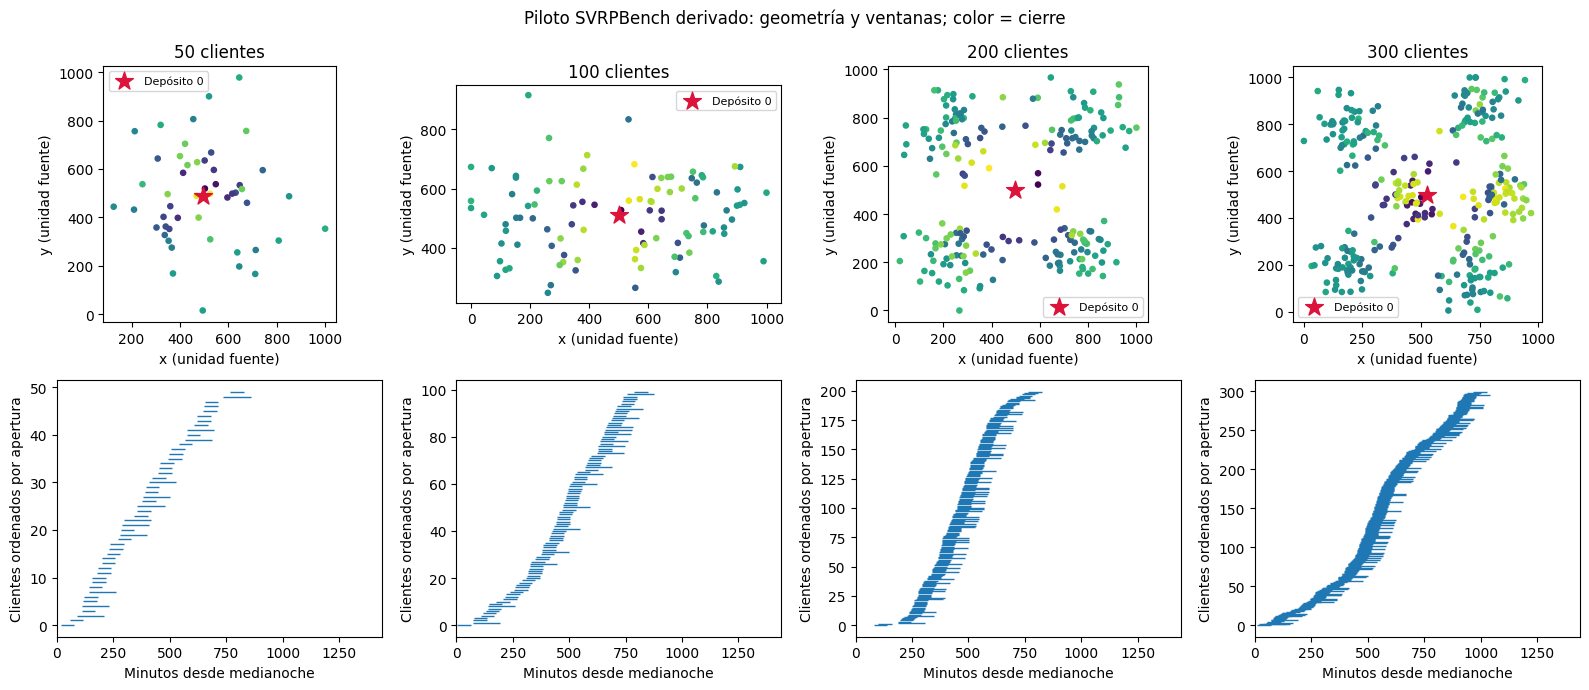

In [8]:
fig, axes = plt.subplots(2,len(instances),figsize=(4*len(instances),7),squeeze=False)
for col,x in enumerate(instances):
    ax=axes[0,col]
    points=ax.scatter(x.locations[1:,0],x.locations[1:,1],c=x.windows[1:,1],s=14,cmap='viridis')
    ax.scatter(*x.locations[0],marker='*',s=180,c='crimson',label='Depósito 0')
    ax.set(title=f'{x.n} clientes',xlabel='x (unidad fuente)',ylabel='y (unidad fuente)',aspect='equal')
    ax.legend(fontsize=8)
    idx=np.argsort(x.windows[1:,0])+1
    axes[1,col].hlines(np.arange(x.n),x.windows[idx,0],x.windows[idx,1],lw=1)
    axes[1,col].set(xlabel='Minutos desde medianoche',ylabel='Clientes ordenados por apertura',xlim=(0,1440))
fig.suptitle('Piloto SVRPBench derivado: geometría y ventanas; color = cierre')
fig.tight_layout()
plt.show()

## 8. Reglas de evaluación comunes
`Traffic` adapta las ecuaciones del **código oficial en minutos**, sin multiplicar accidentes para
hacerlos visibles. En esta parametrización los accidentes pueden ser raros; eso se informa, no se
corrige después de ver resultados. No se reutiliza una matriz estocástica almacenada y se le vuelve a
sumar ruido: los tiempos se calculan desde distancias euclídeas flotantes y el reloj de cada vehículo.

Los números aleatorios se indexan por instancia, escenario, arco dirigido y minuto. Así no dependen
del método ni del orden de evaluación. Esta es una adaptación CRN explícita; no se afirma que reproduzca
bit a bit las simulaciones del artículo, ni que implemente correlaciones espaciales o propiedad FIFO.

Dos políticas comunes: `fixed_order` (esperar apertura y conservar orden) y `causal_edd` (si el próximo
cliente se proyecta tarde, priorizar un pendiente aún alcanzable cuyo cierre sea más próximo). Esta
segunda política es una decisión experimental de la tesis, no una política oficial de SVRPBench.
Sólo ve reloj actual y tiempos esperados; nunca consulta escenarios futuros. No cambia asignación
vehículo-cliente ni añade vehículos. La tardanza ya ocurrida sigue contándose.

Se reportan por separado tiempo de viaje, espera, tardanza, regreso tardío, flota y factibilidad estricta.
CVaR se aplica al tiempo de viaje. No se inventa un peso monetario de tardanza ni una mejora mínima
favorable al método. Antes de entrenar HBG se fijará el objetivo completo que evite premiar rutas baratas
pero infactibles. `net_execution_delta_minutes` es C−c (puede ser negativo), no costo óptimo de recurso.

In [9]:
traffic = p.Traffic(**CONFIG['traffic'])
# Pruebas manuales independientes de los datos descargados.
tiny = p.freeze_instance(dict(instance_id='manual',depot_indices=[0],locations=[[0,0],[3,0],[6,0]],
    demands=[0,0,1],capacities=[5],windows=[[0,100],[5,10],[0,100]],appear_times=[0,0,0],
    provenance={'kind':'manual_validation'}))
r=p.simulate(tiny,[[1,2]],1,p.Traffic(mode='no_noise'))
assert r['travel_minutes']==12 and r['waiting_minutes']==2 and r['strict_feasible']
# Control negativo: misma geometría, plazo de retorno imposible (6+6 > 8).
negative = tiny.payload(); negative['windows'][0] = [0,8]
negative = p.freeze_instance(negative)
assert not p.simulate(negative,[[1,2]],1,p.Traffic(mode='no_noise'))['strict_feasible']
assert p.audit_instance(negative)['proven_infeasible_by_lower_bound']
assert p.empirical_cvar([1,2,3,10],.5)==6.5
assert np.isclose(p.empirical_cvar([1,2,3,10],.2),15.2/3.2)
try: p.validate_routes(tiny,[[2]])
except ValueError: pass
else: raise AssertionError('No detectó un cliente de demanda cero omitido.')
a=p.travel_time(20,480,0,1,'manual',22,traffic)
_ = p.travel_time(20,500,1,2,'manual',33,traffic)
assert a==p.travel_time(20,480,0,1,'manual',22,traffic)
print('Casos manuales y CRN: correctos.')

Casos manuales y CRN: correctos.


## 9. Una solución diagnóstica por tamaño
Primero se verifica y evalúa la **solución testigo** como control positivo; sus resultados se guardan
por separado y nunca participan en una clasificación de métodos. No se exige FR estocástica=1.

La heurística ordena por cierre y asigna por tardanza proyectada e incremento de recorrido, con
restricciones de capacidad. **No es OR-Tools, HBG, GFACS ni una reproducción del baseline del artículo.**
Sirve para probar end-to-end el contrato. Puede producir una ruta estructuralmente válida que incumpla
ventanas; se mostrará como tal, incluyendo su factibilidad nominal. Si su FR es cero mientras el testigo
es nominalmente factible, la instancia sí admite una solución y el fallo pertenece a la heurística.
Las dos políticas se evalúan sin escoger ganadora utilizando evaluación.
Cada tamaño guarda un bloque sellado al finalizar, de modo que una interrupción no borre los anteriores.

In [10]:
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:8]
RUN_ROOT = WORK/'runs'/BANK_ID/RUN_ID
RUN_ROOT.mkdir(parents=True,exist_ok=False)
all_summaries=[]
quality_controls=[]
solutions={}
for x in instances:
    out=RUN_ROOT/f'n{x.n:04d}'
    out.mkdir()
    scenario_file=json.loads((BANK/f'scenarios/n{x.n:04d}.json').read_text())
    certificate=json.loads((BANK/f'certificates/n{x.n:04d}.json').read_text())
    nominal_check=p.verify_certificate(x,certificate,traffic)
    control,control_records=p.evaluate(x,certificate['routes'],scenario_file['evaluation'],
                                      traffic,'fixed_order',CONFIG['alpha_cvar'])
    control.update(method='construction_witness',role='quality_control_only',n=x.n,
                   nominal_strict_feasible=nominal_check['strict_feasible'])
    quality_controls.append(control)
    p.write_json(out/'quality_control_summary.json',control)
    pd.DataFrame(control_records).to_csv(out/'quality_control_scenarios.csv',index=False)
    print(x.n,'testigo nominal: factible; FR estocástica:',control['scenario_strict_feasibility'],flush=True)
    try:
        started=time.perf_counter()
        routes=p.diagnostic_greedy(x,traffic)
        solve_seconds=time.perf_counter()-started
    except ValueError as exc:
        p.write_json(out/'failure.json',{'instance_id':x.instance_id,'method':'diagnostic_greedy',
            'status':'construction_failed','message':str(exc),'not_a_proof_of_infeasibility':True})
        p.seal_bundle(out)
        if DRIVE_ROOT: p.sync_verified(out,DRIVE_ROOT/'runs'/BANK_ID/RUN_ID/out.name)
        print(x.n,'construcción falló; el fallo se conserva.'); continue
    solutions[x.n]=routes
    p.write_json(out/'solution.json',{'method':'diagnostic_greedy','routes':routes,
        'instance_sha256':x.sha,'bank_id':BANK_ID,'solve_seconds':solve_seconds,
        'information_used':'instance and expected times only; no evaluation scenarios'})
    for policy in CONFIG['policies']:
        nominal_spec=p.Traffic(**(CONFIG['traffic'] | {'mode':'nominal_mean'}))
        nominal=p.simulate(x,routes,0,nominal_spec,policy)
        summary,records=p.evaluate(x,routes,scenario_file['evaluation'],traffic,policy,CONFIG['alpha_cvar'])
        summary.update(method='diagnostic_greedy',solve_seconds=solve_seconds,role='development_only',
                       nominal_strict_feasible=nominal['strict_feasible'])
        all_summaries.append(summary)
        p.write_json(out/f'{policy}_summary.json',summary)
        pd.DataFrame(records).to_csv(out/f'{policy}_scenarios.csv',index=False)
        example=p.simulate(x,routes,scenario_file['evaluation'][0],traffic,policy,trace=True)
        p.write_json(out/f'{policy}_first_trace.json',example)
        print(x.n,policy,'factibilidad nominal:',nominal['strict_feasible'],
              'FR estocástica:',round(summary['scenario_strict_feasibility'],4),
              'viaje medio:',round(summary['mean_travel_minutes'],2),flush=True)
    p.write_json(out/'environment.json',ENVIRONMENT)
    p.seal_bundle(out)
    if DRIVE_ROOT: p.sync_verified(out,DRIVE_ROOT/'runs'/BANK_ID/RUN_ID/out.name)
summary_table=pd.DataFrame(all_summaries)
control_table=pd.DataFrame(quality_controls)
print('Controles de calidad (no comparadores):')
display(control_table[['n','nominal_strict_feasible','scenario_strict_feasibility']])
print('Heurística diagnóstica:')
display(summary_table)
print('Directorio de resultados:',RUN_ROOT)

50 testigo nominal: factible; FR estocástica: 1.0


50 fixed_order factibilidad nominal: False FR estocástica: 0.0 viaje medio: 10796.55


50 causal_edd factibilidad nominal: False FR estocástica: 0.0 viaje medio: 11055.47


100 testigo nominal: factible; FR estocástica: 1.0


100 fixed_order factibilidad nominal: True FR estocástica: 1.0 viaje medio: 19103.08


...

Controles de calidad (no comparadores):


,n,nominal_strict_feasible,scenario_strict_feasibility
0,50,True,1.0
1,100,True,1.0
2,200,True,1.0
3,300,True,1.0


Heurística diagnóstica:


,instance_id,instance_sha256,policy,scenarios,alpha,mean_travel_minutes,cvar_travel_minutes,cost_variance_population,scenario_strict_feasibility,mean_customer_violation_fraction,mean_lateness_minutes,mean_depot_overtime_minutes,used_vehicles,evaluation_seconds,method,solve_seconds,role,nominal_strict_feasible
0,dev_tw_n50_i0_fw_v2,cb57f1068a3c7b173dbd087154f8276a8ba98df7cb45cc...,fixed_order,256,0.95,10796.552561,10797.106548,0.065642,0.000000,0.124375,232.539679,0.0,12,0.375704,diagnostic_greedy,0.002901,development_only,False
1,dev_tw_n50_i0_fw_v2,cb57f1068a3c7b173dbd087154f8276a8ba98df7cb45cc...,causal_edd,256,0.95,11055.473370,11241.406507,8155.281651,0.000000,0.121719,567.524224,0.0,12,0.348291,diagnostic_greedy,0.002901,development_only,False
2,dev_tw_n100_i0_fw_v2,3e70717e9302373d12ddf25c613ef3c84522ba6c4f8a73...,fixed_order,256,0.95,19103.079012,19103.915365,0.144339,1.000000,0.000000,0.000000,0.0,22,0.634051,diagnostic_greedy,0.011675,development_only,True
3,dev_tw_n100_i0_fw_v2,3e70717e9302373d12ddf25c613ef3c84522ba6c4f8a73...,causal_edd,256,0.95,19103.079012,19103.915365,0.144339,1.000000,0.000000,0.000000,0.0,22,0.682243,diagnostic_greedy,0.011675,development_only,True
4,dev_tw_n200_i0_fw_v2,387948482f58d7f1e8d6c109f5edcbcc59ea318660b166...,fixed_order,256,0.95,42139.054999,42140.174435,0.257731,0.679688,0.001602,0.015757,0.0,43,1.421148,diagnostic_greedy,0.042790,development_only,True
5,dev_tw_n200_i0_fw_v2,387948482f58d7f1e8d6c109f5edcbcc59ea318660b166...,causal_edd,256,0.95,42146.662224,42165.432279,138.259863,0.601562,0.001992,115.541796,0.0,43,1.502560,diagnostic_greedy,0.042790,development_only,True
6,dev_tw_n300_i0_fw_v2,d2c4b2457c08cf9fa7981fa13a85bd0637ea914ef9eb28...,fixed_order,256,0.95,53399.581244,53400.822613,0.316220,1.000000,0.000000,0.000000,0.0,51,2.286130,diagnostic_greedy,0.099093,development_only,True
7,dev_tw_n300_i0_fw_v2,d2c4b2457c08cf9fa7981fa13a85bd0637ea914ef9eb28...,causal_edd,256,0.95,53399.581244,53400.822613,0.316220,1.000000,0.000000,0.000000,0.0,51,2.421079,diagnostic_greedy,0.099093,development_only,True


Directorio de resultados: /Users/abrahamcastanedaquintero/Documents/ChatGPT/TESIS/tmp/notebook00-execution/runs/pilot00_d7af5a7db106f2f9/20260917T010126Z_db15127c


## 10. Rutas y costos: lectura descriptiva
Los tiempos medidos aquí describen esta sesión y hardware, no una comparación de métodos. Con una
sola instancia por escala no se calculan ANOVA, Friedman ni p-valores. En ejecuciones largas, aumentar
escenarios sirve para precisión Monte Carlo, no reemplaza las instancias independientes.

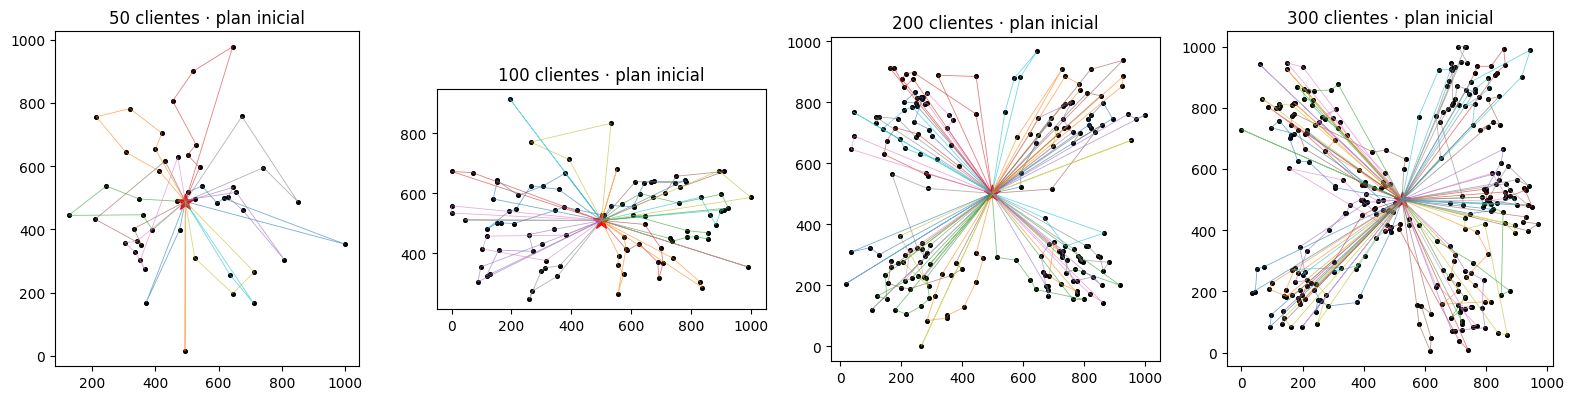

Resultados locales verificados: /Users/abrahamcastanedaquintero/Documents/ChatGPT/TESIS/tmp/notebook00-execution/runs/pilot00_d7af5a7db106f2f9/20260917T010126Z_db15127c/report


In [11]:
fig,axes=plt.subplots(1,len(instances),figsize=(4*len(instances),4),squeeze=False)
for col,x in enumerate(instances):
    ax=axes[0,col]
    for route in solutions.get(x.n,[]):
        if route:
            coords=x.locations[[0]+route+[0]]
            ax.plot(coords[:,0],coords[:,1],lw=.6,alpha=.6)
    ax.scatter(x.locations[1:,0],x.locations[1:,1],s=7,c='black')
    ax.scatter(*x.locations[0],marker='*',s=140,c='red')
    ax.set(title=f'{x.n} clientes · plan inicial',aspect='equal')
fig.tight_layout(); plt.show()
REPORT=RUN_ROOT/'report'; REPORT.mkdir()
fig.savefig(REPORT/'routes.png',dpi=160,bbox_inches='tight')
summary_table.to_csv(REPORT/'summary.csv',index=False)
control_table.to_csv(REPORT/'quality_controls.csv',index=False)
p.write_json(REPORT/'run.json',{'run_id':RUN_ID,'bank_id':BANK_ID,
    'bank_manifest_sha256':p.verify_bundle(BANK),'role':'development_only',
    'environment':ENVIRONMENT,'hypothesis_testing':False})
p.seal_bundle(REPORT)
if DRIVE_ROOT:
    p.sync_verified(REPORT,DRIVE_ROOT/'runs'/BANK_ID/RUN_ID/'report')
    print('Resultados y gráfico verificados en:',DRIVE_ROOT/'runs'/BANK_ID/RUN_ID)
else:
    print('Resultados locales verificados:',REPORT)

## 11. Contrato para los métodos siguientes
Todos deben cargar el mismo banco sellado, mantener depósito/flota/clientes/unidades y devolver
`routes`: una lista por vehículo, sin incluir el depósito. Las listas vacías representan vehículos
no usados. El evaluador añade salida y regreso al depósito y comprueba la cobertura completa.
No aceptar directamente las métricas que reporte el solver: volver a evaluar sus rutas aquí.
`load_bank` comprueba manifiesto, versión, código, tamaños y certificados nominales. Los certificados
son para auditoría: no entregarlos a ningún método como entrenamiento, solución inicial ni presupuesto
de búsqueda gratuito. V1 y v2 tienen IDs y hashes diferentes; no combinar sus resultados.

```python
import sys
sys.path.insert(0, str(BANK / 'code'))  # su __pycache__ no invalida el sello
import svrplab_pilot as shared
instances = shared.load_bank(BANK)
# routes = mi_metodo(instance, datos_permitidos, presupuesto)
shared.validate_routes(instance, routes)
# Usar train/selection para entrenar y seleccionar, evaluation sólo para informar.
summary, raw = shared.evaluate(instance, routes, evaluation_seeds, traffic, 'causal_edd')
```

Antes de comparar AM/POMO/ACO/HBG: fijar presupuestos de construcción/búsqueda, reportar entrenamiento
y tuning por separado, registrar hardware, y comprobar máscaras/objetivo con los casos manuales.
No otorgar más vehículos, más escenarios de selección o más tiempo al método propuesto. Si se utilizan
presupuestos largos, mostrar curvas calidad-tiempo y cantidades de evaluaciones, sin imponer ahora
un umbral de milisegundos ni un porcentaje de mejora sin justificación operativa.

**Pendientes científicos visibles:** calibración de congestión/accidentes, sensibilidad a ventanas
reconstruidas, objetivo sensible al riesgo con tratamiento de fallos, integración RL4CO, baselines y
entrenamiento HBG. ENN continúa como extensión opcional. El siguiente notebook debe implementar un
comparador y usar este contrato, no regenerar sus propias instancias.

### Fuentes
- Heakl et al., [SVRPBench](https://arxiv.org/abs/2505.21887), ecuaciones de tráfico y métricas.
- [Código SVRPBench fijado](https://github.com/yehias21/svrpbench/tree/9fd5737ae598e1667ae94907f9c45224c501c84b).
- [Dataset](https://huggingface.co/datasets/MBZUAI/svrp-bench).
- Gendreau, Laporte y Séguin (1996), *Stochastic vehicle routing*: recurso dependiente de la información disponible.
- Rockafellar y Uryasev (2000), *Optimization of Conditional Value-at-Risk*: CVaR por escenarios.
- [Límites de Colab](https://research.google.com/colaboratory/faq.html): GPU disponible y duración variables.